## **Credit Card Fraud Detection - Machine learning** ##


**Built classification model to detect potential fraud.
Performed feature engineering, outlier removal, and model comparison.
Tools: Python, scikit-learn.**

In [1]:
# Step 1: Import all required libraries

import pandas as pd              # for data handling (tables)
import numpy as np               # for numerical operations

import matplotlib.pyplot as plt  # for plots
import seaborn as sns            # for nicer plots

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score
)

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from imblearn.over_sampling import SMOTE   # for handling class imbalance

import pickle   # for saving trained model


**Explanation**

* pandas, numpy → handle and process data.

* matplotlib, seaborn → charts and graphs (EDA).

* train_test_split → split data into train and test.

* StandardScaler → scale numerical features.

* classification_report, confusion_matrix, roc_auc_score → model evaluation.

* LogisticRegression, RandomForestClassifier → ML models.

* SMOTE → oversamples minority class (fraud) to balance data.

* pickle → save trained model and scaler to disk.

In [4]:
# Step 2: Load the CSV file

df = pd.read_csv("/content/creditcard.csv")   # Ensure this file is in your working directory
df.head()


/tmp/ipython-input-1609429483.py:3: DtypeWarning: Columns (22) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("/content/creditcard.csv")   # Ensure this file is in your working directory


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0.0
1,0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0.0
2,1,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0.0
3,1,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0.0
4,2,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0.0


**Explanation**

* pd.read_csv("creditcard.csv") → reads the dataset into a DataFrame called df.

* df.head() → shows the first 5 rows to confirm it loaded correctly.

In [7]:
# Step 3: Basic structure of the data

print("Shape of data:", df.shape)
print("\nInfo:")
print(df.info())

print("\nSummary statistics:")
display(df.describe())

# Check target variable distribution
print("\nClass distribution (count):")
print(df['Class'].value_counts())

print("\nClass distribution (percentage):")
print(df['Class'].value_counts(normalize=True) * 100)


Shape of data: (33760, 31)

Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 33760 entries, 0 to 33759
Data columns (total 31 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Time    33760 non-null  int64  
 1   V1      33760 non-null  float64
 2   V2      33760 non-null  float64
 3   V3      33760 non-null  float64
 4   V4      33760 non-null  float64
 5   V5      33760 non-null  float64
 6   V6      33760 non-null  float64
 7   V7      33760 non-null  float64
 8   V8      33760 non-null  float64
 9   V9      33760 non-null  float64
 10  V10     33760 non-null  float64
 11  V11     33760 non-null  float64
 12  V12     33760 non-null  float64
 13  V13     33760 non-null  float64
 14  V14     33760 non-null  float64
 15  V15     33760 non-null  float64
 16  V16     33760 non-null  float64
 17  V17     33760 non-null  float64
 18  V18     33760 non-null  float64
 19  V19     33760 non-null  float64
 20  V20     33760 non-null  float64
 21  V

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V20,V21,V23,V24,V25,V26,V27,V28,Amount,Class
count,33760.000000,33760.000000,33760.000000,33760.000000,33760.000000,33760.000000,33760.000000,33760.000000,33760.000000,33760.000000,...,33760.000000,33760.000000,33759.000000,33759.000000,33759.000000,33759.000000,33759.000000,33759.000000,33759.000000,33759.000000
mean,23186.502044,-0.210769,0.090212,0.718086,0.205183,-0.215343,0.092961,-0.118041,0.031774,0.285485,...,0.044957,-0.031917,-0.042490,0.008641,0.135181,0.021953,0.012227,0.003599,83.034366,0.003051
std,12310.554703,1.849230,1.545474,1.565917,1.413512,1.397150,1.312452,1.270591,1.257190,1.243503,...,0.671623,0.778003,0.544158,0.591997,0.435728,0.507048,0.388694,0.303696,227.868983,0.055153
min,0.000000,-30.552380,-40.978852,-31.103685,-5.172595,-42.147898,-23.496714,-26.548144,-41.484823,-7.175097,...,-13.694584,-20.262054,-26.751119,-2.836627,-7.495741,-1.338556,-8.567638,-9.617915,0.000000,0.000000
25%,11323.250000,-0.957639,-0.480557,0.248743,-0.705571,-0.813268,-0.646448,-0.598428,-0.156904,-0.504769,...,-0.160852,-0.241145,-0.177751,-0.325370,-0.128167,-0.331954,-0.062816,-0.007200,6.905000,0.000000
50%,28260.500000,-0.240862,0.125560,0.834797,0.194608,-0.251247,-0.165186,-0.072077,0.041389,0.164850,...,-0.022156,-0.084376,-0.051504,0.062636,0.174733,-0.061390,0.009070,0.021002,21.000000,0.000000
75%,33557.250000,1.162820,0.767388,1.460421,1.089341,0.303673,0.479350,0.439445,0.303476,1.025500,...,0.165501,0.091394,0.075396,0.398457,0.420014,0.301171,0.088390,0.076330,75.000000,0.000000
max,37373.000000,1.960497,16.713389,4.101716,13.143668,34.099309,22.529298,36.677268,20.007208,10.392889,...,17.281859,22.614889,13.876221,4.014444,5.525093,3.517346,11.135740,5.678671,7879.420000,1.000000



Class distribution (count):
Class
0.0    33656
1.0      103
Name: count, dtype: int64

Class distribution (percentage):
Class
0.0    99.694896
1.0     0.305104
Name: proportion, dtype: float64


**Explanation**

* df.shape → number of rows and columns.

* df.info() → data types and missing values.

* df.describe() → basic statistics (mean, std, min, etc.).

* df['Class'].value_counts() → how many normal vs fraud.

* normalize=True → gives percentage; usually fraud ≪ non-fraud (high imbalance).

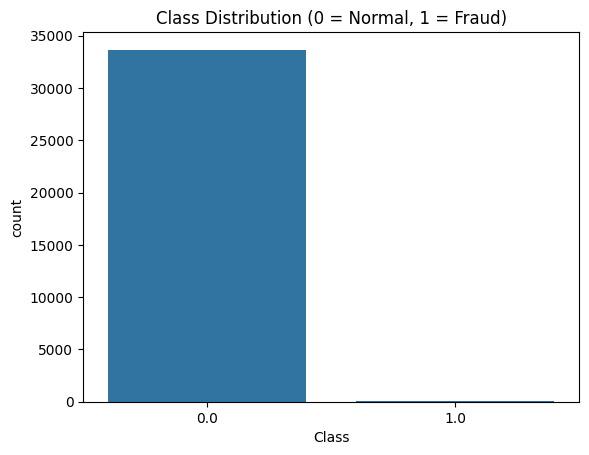

In [6]:
# Step 4: Visualize imbalance in target class

sns.countplot(x='Class', data=df)
plt.title("Class Distribution (0 = Normal, 1 = Fraud)")
plt.show()


**Explanation**

* countplot → bar chart showing how many 0 and 1 are in Class.

* This visually confirms that fraud cases are very rare compared to normal.

In [8]:
# Step 5: Outlier removal using IQR on 'Amount'

Q1 = df['Amount'].quantile(0.25)
Q3 = df['Amount'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)

# Keep only rows within the bounds
df_clean = df[(df['Amount'] >= lower_bound) & (df['Amount'] <= upper_bound)]

print("Original shape:", df.shape)
print("After outlier removal:", df_clean.shape)


Lower bound: -95.2375
Upper bound: 177.14249999999998
Original shape: (33760, 31)
After outlier removal: (30216, 31)


**Explanation**

* Q1, Q3 → 25th and 75th percentiles.

* IQR = Interquartile range = Q3 - Q1.

* Values below Q1 - 1.5*IQR and above Q3 + 1.5*IQR are treated as outliers.

* df_clean → dataset after removing outlier rows from Amount.

In [9]:
# Step 6: Feature Engineering
#Hour → hour of transaction.
#Log_Amount → log transformation of amount.
#High_Amount_Flag → flag for large transactions.

df_fe = df_clean.copy()

# 1. Hour of the day from 'Time' (time is in seconds)
df_fe['Hour'] = (df_fe['Time'] // 3600) % 24

# 2. Log transformation of 'Amount' (to reduce skewness)
df_fe['Log_Amount'] = np.log1p(df_fe['Amount'])

# 3. High amount flag (you can change threshold if you want)
df_fe['High_Amount_Flag'] = (df_fe['Amount'] > 200).astype(int)

df_fe[['Time', 'Amount', 'Hour', 'Log_Amount', 'High_Amount_Flag']].head()


,Time,Amount,Hour,Log_Amount,High_Amount_Flag
0,0,149.62,0,5.014760,0
1,0,2.69,0,1.305626,0
3,1,123.50,0,4.824306,0
4,2,69.99,0,4.262539,0
5,2,3.67,0,1.541159,0


**Explanation**

* df_clean.copy() → work on a safe copy.

* Hour helps capture time patterns in fraud (e.g., more at night).

* np.log1p = log(1 + x) → safer for zero and small values.

* High_Amount_Flag = 1 when Amount > 200; idea is big transactions may be riskier.

In [10]:
# Step 7: Split features (X) and target (y)

X = df_fe.drop('Class', axis=1)   # all columns except target
y = df_fe['Class']                # target column

# Perform train-test split with stratification to keep class ratio same
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Train shape:", X_train.shape, y_train.shape)
print("Test shape:", X_test.shape, y_test.shape)


Train shape: (24172, 33) (24172,)
Test shape: (6044, 33) (6044,)


**Explanation**

* X → independent variables (features).

* y → target variable (Class).

* test_size=0.2 → 80% training, 20% testing.

* stratify=y → keeps same fraud/normal proportion in both train and test.

In [12]:
# Step 8: Scale selected numerical features

scaler = StandardScaler()

# Columns that need scaling (others are already PCA components)
cols_to_scale = ['Time', 'Amount', 'Log_Amount']

# Fit scaler on training set and transform both train and test
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

X_train_scaled[cols_to_scale] = scaler.fit_transform(X_train[cols_to_scale])
X_test_scaled[cols_to_scale] = scaler.transform(X_test[cols_to_scale])


**Explanation**

* StandardScaler converts values to mean 0 and standard deviation 1.

* Fit on training data only → then apply same transformation to test data.

* We keep scaled data in X_train_scaled and X_test_scaled.

In [13]:
# Step 9: Handle class imbalance using SMOTE on training data

smote = SMOTE(random_state=42)

X_train_res, y_train_res = smote.fit_resample(X_train_scaled, y_train)

print("Before SMOTE:")
print(y_train.value_counts())

print("\nAfter SMOTE:")
print(y_train_res.value_counts())


Before SMOTE:
Class
0.0    24097
1.0       75
Name: count, dtype: int64

After SMOTE:
Class
0.0    24097
1.0    24097
Name: count, dtype: int64


**Explanation**

* Fraud cases are rare → model may learn to always predict “non-fraud”.

* SMOTE generates synthetic fraud samples in training data to balance the classes.

* We only apply SMOTE on training data, not on test data.

In [14]:
# Step 10.1: Train Logistic Regression

lr_model = LogisticRegression(max_iter=2000, n_jobs=-1)
lr_model.fit(X_train_res, y_train_res)

# Predictions
y_pred_lr = lr_model.predict(X_test_scaled)


**Explanation**

* max_iter=2000 → allows more iterations to converge.

* n_jobs=-1 → use all CPU cores.

* predict gives predicted class (0 or 1) on test data.

In [16]:
# Step 10.2: Train Random Forest

rf_model = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train_res, y_train_res)

# Predictions
y_pred_rf = rf_model.predict(X_test_scaled)


**Explanation**

* n_estimators=300 → uses 300 decision trees.

* RandomForest often performs very well on tabular data.

* Again, predict gives the class for each test sample.

In [17]:
# Step 11: Evaluation function

def evaluate_model(y_true, y_pred, model_name):
    print(f"\n=== {model_name} ===")
    print("Classification Report:")
    print(classification_report(y_true, y_pred, digits=4))

    print("Confusion Matrix:")
    print(confusion_matrix(y_true, y_pred))

    print("ROC-AUC Score:", roc_auc_score(y_true, y_pred))

# Evaluate Logistic Regression
evaluate_model(y_test, y_pred_lr, "Logistic Regression")

# Evaluate Random Forest
evaluate_model(y_test, y_pred_rf, "Random Forest")



=== Logistic Regression ===
Classification Report:
              precision    recall  f1-score   support

         0.0     0.9995    0.9945    0.9970      6025
         1.0     0.3265    0.8421    0.4706        19

    accuracy                         0.9940      6044
   macro avg     0.6630    0.9183    0.7338      6044
weighted avg     0.9974    0.9940    0.9954      6044

Confusion Matrix:
[[5992   33]
 [   3   16]]
ROC-AUC Score: 0.9183140423673292

=== Random Forest ===
Classification Report:
              precision    recall  f1-score   support

         0.0     0.9993    1.0000    0.9997      6025
         1.0     1.0000    0.7895    0.8824        19

    accuracy                         0.9993      6044
   macro avg     0.9997    0.8947    0.9410      6044
weighted avg     0.9993    0.9993    0.9993      6044

Confusion Matrix:
[[6025    0]
 [   4   15]]
ROC-AUC Score: 0.8947368421052632


**Explanation**

* classification_report → precision, recall, F1 for each class (0 and 1).

* For fraud detection, recall for class 1 is very important.

* confusion_matrix → shows TP, TN, FP, FN.

* roc_auc_score → how well the model separates classes (higher is better).

You can now compare which model performed better on fraud class.

In [18]:
# Step 12: Save trained model and scaler

with open("fraud_model_rf.pkl", "wb") as f:
    pickle.dump(rf_model, f)

with open("scaler.pkl", "wb") as f:
    pickle.dump(scaler, f)

print("Model and scaler saved successfully.")


Model and scaler saved successfully.


**Explanation**

* pickle.dump → writes the object (model/scaler) to disk as a .pkl file.

* Later you can load and use it in another script / API / app.

In [19]:
# Step 13: Demo prediction on a single sample

def predict_fraud(sample_row):
    """
    sample_row: a single-row DataFrame with same columns as X
    returns: predicted class (0/1), fraud probability
    """
    # Make a copy to avoid changing original
    sample = sample_row.copy()

    # Scale the required columns using the fitted scaler
    sample[cols_to_scale] = scaler.transform(sample[cols_to_scale])

    # Get prediction and probability from Random Forest model
    pred_class = rf_model.predict(sample)[0]
    pred_proba = rf_model.predict_proba(sample)[0][1]  # probability of class 1 (fraud)

    return pred_class, pred_proba

# Take one example from test set
sample = X_test.iloc[[0]]
pred, proba = predict_fraud(sample)

print("Predicted class:", pred)           # 0 = normal, 1 = fraud
print("Fraud probability:", proba)


Predicted class: 0.0
Fraud probability: 0.0


**Explanation**

* sample_row → one transaction (1 row from your dataset).

* We scale the numeric columns with the same scaler used during training.

* predict → returns 0 or 1.

* predict_proba → returns probabilities; [0][1] is probability of fraud.